# DCGAN – Healthy Brain MRI 


In [1]:
import os, copy, time
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
import torchvision
from torch.utils.data import DataLoader
from torchvision import transforms, datasets
import matplotlib.pyplot as plt

In [2]:
# ----------------------------- Config -----------------------------
DATA_ROOT = r"F:\Work\ORANGE MODELS\MRI\Generate Healthy MRI Images for Brain"
OUT_DIR   = r"F:\Work\Python Learning"          # checkpoints + sample grids are saved here
IMG_SIZE  = 128
BATCH     = 64
NZ        = 100          # latent size
EPOCHS    = 300
LR        = 2e-4
EMA_DECAY = 0.999
REAL_LABEL = 0.9         # one-sided label smoothing
SAVE_EVERY = 10          # epochs between checkpoints / sample grids
# ------------------------------------------------------------------

torch.manual_seed(42)
os.makedirs(OUT_DIR, exist_ok=True)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

dataset = datasets.ImageFolder(
    root=DATA_ROOT,
    transform=transforms.Compose([
        transforms.Resize((IMG_SIZE, IMG_SIZE)),
        transforms.ToTensor(),
        transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5)),
    ]),
)
dataloader = DataLoader(dataset, batch_size=BATCH, shuffle=True, drop_last=True, pin_memory=(device.type == "cuda"))
print(f"Dataset size: {len(dataset)} images")

Using device: cuda
Dataset size: 10150 images


In [3]:
class Generator(nn.Module):
    def __init__(self, noise_dim=100):
        super().__init__()
        def up(i, o):
            return [nn.ConvTranspose2d(i, o, 4, 2, 1, bias=False), nn.BatchNorm2d(o), nn.ReLU(True)]
        self.layers = nn.Sequential(
            # (100,1,1) -> (512,4,4)
            nn.ConvTranspose2d(noise_dim, 512, 4, 1, 0, bias=False), nn.BatchNorm2d(512), nn.ReLU(True),
            *up(512, 512),   # 8x8
            *up(512, 256),   # 16x16
            *up(256, 128),   # 32x32
            *up(128, 64),    # 64x64
            nn.ConvTranspose2d(64, 3, 4, 2, 1, bias=False),  # 128x128
            nn.Tanh(),
        )

    def forward(self, x):
        return self.layers(x)

In [4]:
class MinibatchStd(nn.Module):
    """Appends the batch-wise feature std as an extra channel. If G collapses, this
    channel goes to ~0 for fakes, so D can easily spot (and punish) the lack of variety."""
    def forward(self, x):
        std = x.std(dim=0, unbiased=False).mean()
        return torch.cat([x, std.expand(x.size(0), 1, x.size(2), x.size(3))], dim=1)


class Discriminator(nn.Module):
    def __init__(self):
        super().__init__()
        SN = nn.utils.spectral_norm
        def down(i, o):
            return [SN(nn.Conv2d(i, o, 4, 2, 1, bias=False)), nn.LeakyReLU(0.2, inplace=True)]
        self.layers = nn.Sequential(
            *down(3, 64),      # 64x64
            *down(64, 128),    # 32x32
            *down(128, 256),   # 16x16
            *down(256, 512),   # 8x8
            *down(512, 512),   # 4x4
            MinibatchStd(),    # 513 channels
            SN(nn.Conv2d(513, 1, 4, 1, 0, bias=False)),   # raw logit (no Sigmoid)
        )

    def forward(self, x):
        return self.layers(x).view(-1)


def init_weights(m):
    if isinstance(m, (nn.Conv2d, nn.ConvTranspose2d)):
        nn.init.normal_(m.weight, 0.0, 0.02)
    elif isinstance(m, nn.BatchNorm2d):
        nn.init.normal_(m.weight, 1.0, 0.02)
        nn.init.zeros_(m.bias)

In [5]:
# ---------------- DiffAugment (applied to ALL images D sees) ----------------
def _brightness(x):
    return x + (torch.rand(x.size(0), 1, 1, 1, device=x.device) - 0.5)

def _contrast(x):
    m = x.mean(dim=[1, 2, 3], keepdim=True)
    return (x - m) * (torch.rand(x.size(0), 1, 1, 1, device=x.device) + 0.5) + m

def _translation(x, ratio=0.125):
    B, _, H, W = x.shape
    sx, sy = int(H * ratio + 0.5), int(W * ratio + 0.5)
    tx = torch.randint(-sx, sx + 1, (B, 1, 1), device=x.device)
    ty = torch.randint(-sy, sy + 1, (B, 1, 1), device=x.device)
    gb, gx, gy = torch.meshgrid(torch.arange(B, device=x.device),
                                torch.arange(H, device=x.device),
                                torch.arange(W, device=x.device), indexing="ij")
    gx = torch.clamp(gx + tx + 1, 0, H + 1)
    gy = torch.clamp(gy + ty + 1, 0, W + 1)
    xp = F.pad(x, [1, 1, 1, 1])
    return xp.permute(0, 2, 3, 1).contiguous()[gb, gx, gy].permute(0, 3, 1, 2)

def _cutout(x, ratio=0.4):
    B, _, H, W = x.shape
    ch, cw = int(H * ratio + 0.5), int(W * ratio + 0.5)
    ox = torch.randint(0, H + (1 - ch % 2), (B, 1, 1), device=x.device)
    oy = torch.randint(0, W + (1 - cw % 2), (B, 1, 1), device=x.device)
    gb, gx, gy = torch.meshgrid(torch.arange(B, device=x.device),
                                torch.arange(ch, device=x.device),
                                torch.arange(cw, device=x.device), indexing="ij")
    gx = torch.clamp(gx + ox - ch // 2, 0, H - 1)
    gy = torch.clamp(gy + oy - cw // 2, 0, W - 1)
    mask = torch.ones(B, H, W, device=x.device, dtype=x.dtype)
    mask[gb, gx, gy] = 0
    return x * mask.unsqueeze(1)

def diff_augment(x):
    x = _brightness(x)
    x = _contrast(x)
    x = _translation(x)
    x = _cutout(x)
    return x

In [6]:
netG = Generator(NZ).to(device)
netD = Discriminator().to(device)
netG.apply(init_weights)            # D keeps spectral-norm's own init

netG_ema = copy.deepcopy(netG).eval()
for p in netG_ema.parameters():
    p.requires_grad_(False)

@torch.no_grad()
def update_ema(ema, model, decay=EMA_DECAY):
    for pe, p in zip(ema.parameters(), model.parameters()):
        pe.mul_(decay).add_(p.detach(), alpha=1 - decay)
    for be, b in zip(ema.buffers(), model.buffers()):
        be.copy_(b)

criterion = nn.BCEWithLogitsLoss()
optimizer_G = optim.Adam(netG.parameters(), lr=LR, betas=(0.5, 0.999))
optimizer_D = optim.Adam(netD.parameters(), lr=LR, betas=(0.5, 0.999))

fixed_noise = torch.randn(25, NZ, 1, 1, device=device)

print(f"G params: {sum(p.numel() for p in netG.parameters())/1e6:.1f}M | D params: {sum(p.numel() for p in netD.parameters())/1e6:.1f}M")

G params: 7.8M | D params: 7.0M


In [7]:
# ---------------- Diversity score ----------------
# Mean pairwise distance between images (32x32 grayscale), generated / real.
# ~1.0 = as varied as real data. Well below ~0.7 = mode collapse (repeats).
def _small(x):
    return F.adaptive_avg_pool2d(x.mean(1, keepdim=True), 32).flatten(1)

def mean_pairwise_dist(x):
    d = torch.cdist(x, x)
    n = x.size(0)
    return d.sum() / (n * (n - 1))

@torch.no_grad()
def diversity_ratio(gen, real_ref, n=256):
    z = torch.randn(n, NZ, 1, 1, device=device)
    fake = gen(z)
    return (mean_pairwise_dist(_small(fake)) / mean_pairwise_dist(_small(real_ref))).item()

# reference batch of real images
_ref_loader = DataLoader(dataset, batch_size=256, shuffle=True)
real_ref = next(iter(_ref_loader))[0].to(device)
print("Real-data reference ready.")

Real-data reference ready.


In [8]:
def save_grid(gen, path, title=None):
    gen.eval()
    with torch.no_grad():
        imgs = (gen(fixed_noise) + 1) / 2
    grid = torchvision.utils.make_grid(imgs.cpu(), nrow=5)
    torchvision.utils.save_image(grid, path)
    return grid

history = {"D": [], "G": [], "div": [], "div_ema": []}
t0 = time.time()

for epoch in range(EPOCHS):
    netG.train(); netD.train()
    sum_D = sum_G = 0.0

    for real_images, _ in dataloader:
        real_images = real_images.to(device, non_blocking=True)
        B = real_images.size(0)

        # ---------------- Train Discriminator ----------------
        noise = torch.randn(B, NZ, 1, 1, device=device)
        fake_images = netG(noise)

        optimizer_D.zero_grad()
        out_real = netD(diff_augment(real_images))
        out_fake = netD(diff_augment(fake_images.detach()))
        loss_D = criterion(out_real, torch.full((B,), REAL_LABEL, device=device)) \
               + criterion(out_fake, torch.zeros(B, device=device))
        loss_D.backward()
        optimizer_D.step()

        # ---------------- Train Generator ----------------
        optimizer_G.zero_grad()
        out = netD(diff_augment(fake_images))
        loss_G = criterion(out, torch.ones(B, device=device))
        loss_G.backward()
        optimizer_G.step()

        update_ema(netG_ema, netG)
        sum_D += loss_D.item(); sum_G += loss_G.item()

    n_it = len(dataloader)
    div = div_ema = float("nan")
    if (epoch + 1) % 5 == 0:
        netG.eval()
        div = diversity_ratio(netG, real_ref)
        div_ema = diversity_ratio(netG_ema, real_ref)
        netG.train()
    history["D"].append(sum_D / n_it); history["G"].append(sum_G / n_it)
    history["div"].append(div); history["div_ema"].append(div_ema)

    msg = f"Epoch [{epoch+1}/{EPOCHS}] | D: {sum_D/n_it:.3f} | G: {sum_G/n_it:.3f}"
    if div == div:
        msg += f" | diversity G: {div:.2f}  EMA: {div_ema:.2f}"
    print(msg + f" | {(time.time()-t0)/60:.1f} min")

    if (epoch + 1) % SAVE_EVERY == 0:
        save_grid(netG_ema, os.path.join(OUT_DIR, f"samples_ema_epoch{epoch+1:03d}.png"))
        torch.save({"epoch": epoch + 1, "G": netG.state_dict(), "G_ema": netG_ema.state_dict(), "noise_dim": NZ},
                   os.path.join(OUT_DIR, f"mri_dcgan_epoch{epoch+1:03d}.pth"))

Epoch [1/300] | D: 1.344 | G: 0.718 | 0.5 min
Epoch [2/300] | D: 1.353 | G: 0.719 | 1.0 min
Epoch [3/300] | D: 1.334 | G: 0.725 | 1.4 min
Epoch [4/300] | D: 1.300 | G: 0.759 | 1.9 min
Epoch [5/300] | D: 1.296 | G: 0.749 | diversity G: 0.31  EMA: 0.01 | 2.4 min
Epoch [6/300] | D: 1.304 | G: 0.757 | 2.8 min
Epoch [7/300] | D: 1.317 | G: 0.755 | 3.3 min
Epoch [8/300] | D: 1.330 | G: 0.761 | 3.8 min
Epoch [9/300] | D: 1.334 | G: 0.747 | 4.2 min
Epoch [10/300] | D: 1.329 | G: 0.757 | diversity G: 0.48  EMA: 0.21 | 4.7 min
Epoch [11/300] | D: 1.318 | G: 0.772 | 5.2 min
Epoch [12/300] | D: 1.316 | G: 0.770 | 5.6 min
Epoch [13/300] | D: 1.309 | G: 0.765 | 6.1 min
Epoch [14/300] | D: 1.297 | G: 0.787 | 6.6 min
Epoch [15/300] | D: 1.291 | G: 0.782 | diversity G: 0.56  EMA: 0.44 | 7.0 min
Epoch [16/300] | D: 1.294 | G: 0.805 | 7.5 min
Epoch [17/300] | D: 1.298 | G: 0.793 | 7.9 min
Epoch [18/300] | D: 1.291 | G: 0.795 | 8.4 min
Epoch [19/300] | D: 1.301 | G: 0.784 | 8.9 min
Epoch [20/300] | D: 1.3

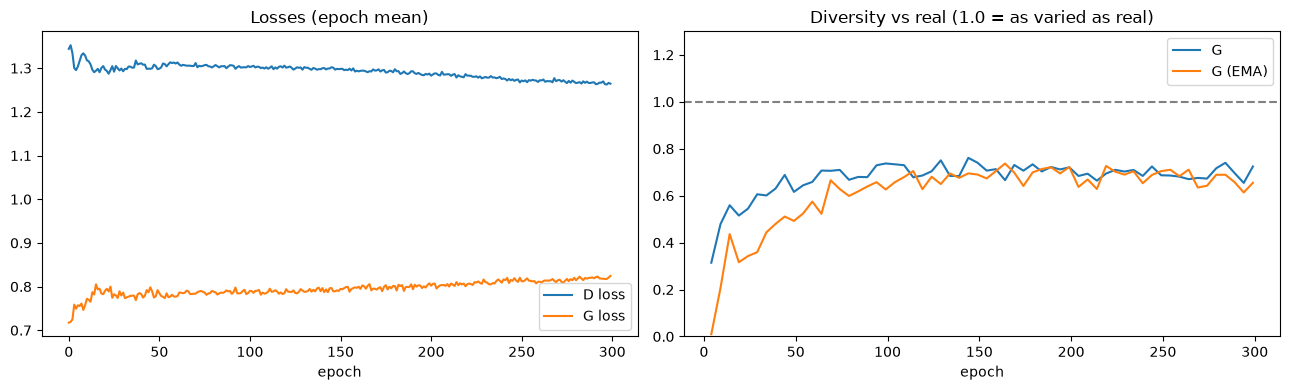

In [9]:
# Training curves + diversity over time
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].plot(history["D"], label="D loss"); ax[0].plot(history["G"], label="G loss")
ax[0].set_xlabel("epoch"); ax[0].legend(); ax[0].set_title("Losses (epoch mean)")
ep = [i for i, v in enumerate(history["div"]) if v == v]
ax[1].plot(ep, [history["div"][i] for i in ep], label="G")
ax[1].plot(ep, [history["div_ema"][i] for i in ep], label="G (EMA)")
ax[1].axhline(1.0, ls="--", c="gray"); ax[1].set_ylim(0, 1.3)
ax[1].set_xlabel("epoch"); ax[1].legend(); ax[1].set_title("Diversity vs real (1.0 = as varied as real)")
plt.tight_layout(); plt.show()

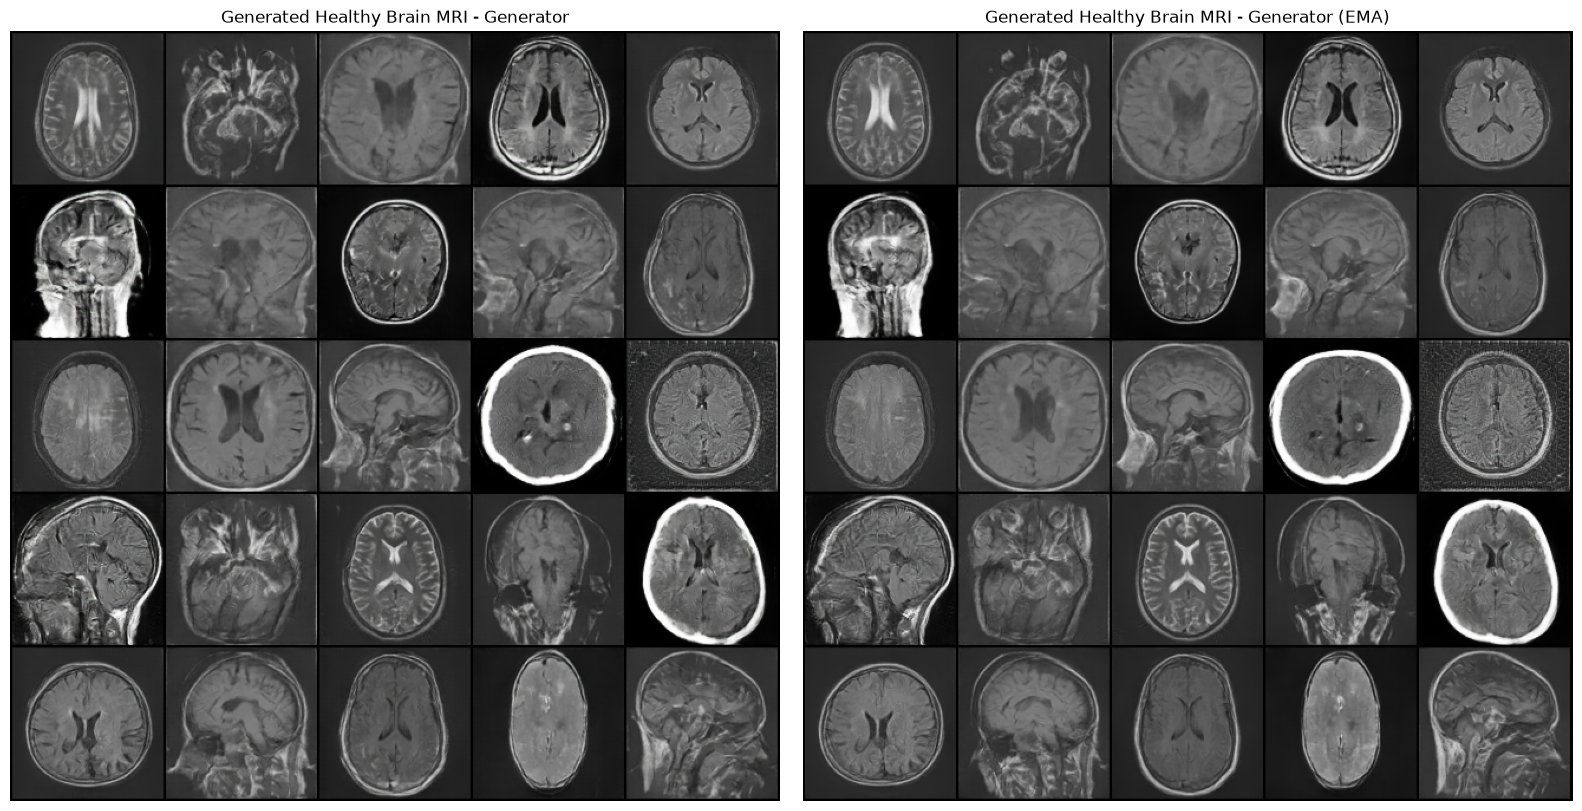

In [11]:
# Compare raw G vs EMA G on the same noise
netG.eval(); netG_ema.eval()
fig, axes = plt.subplots(1, 2, figsize=(16, 8))
for a, (name, g) in zip(axes, [("Generator", netG), ("Generator (EMA)", netG_ema)]):
    with torch.no_grad():
        imgs = (g(fixed_noise) + 1) / 2
    grid = torchvision.utils.make_grid(imgs.cpu(), nrow=5)
    a.imshow(grid.permute(1, 2, 0)); a.axis("off"); a.set_title(f"Generated Healthy Brain MRI - {name}")
plt.tight_layout(); plt.show()

In [12]:
torch.save({"G": netG.state_dict(), "G_ema": netG_ema.state_dict(), "noise_dim": NZ},
           os.path.join(OUT_DIR, "Healthy MRI of Brain v2.pth"))
print("Generator saved successfully!")

Generator saved successfully!


## Generate from a saved model
Run this cell alone (after a restart) to sample from a saved checkpoint. Use the EMA weights unless the raw ones look better.
Checkpoints from every `SAVE_EVERY` epochs are also in `OUT_DIR` - if the final one has repeats, try an earlier epoch (check `samples_ema_epoch*.png` and the diversity score).

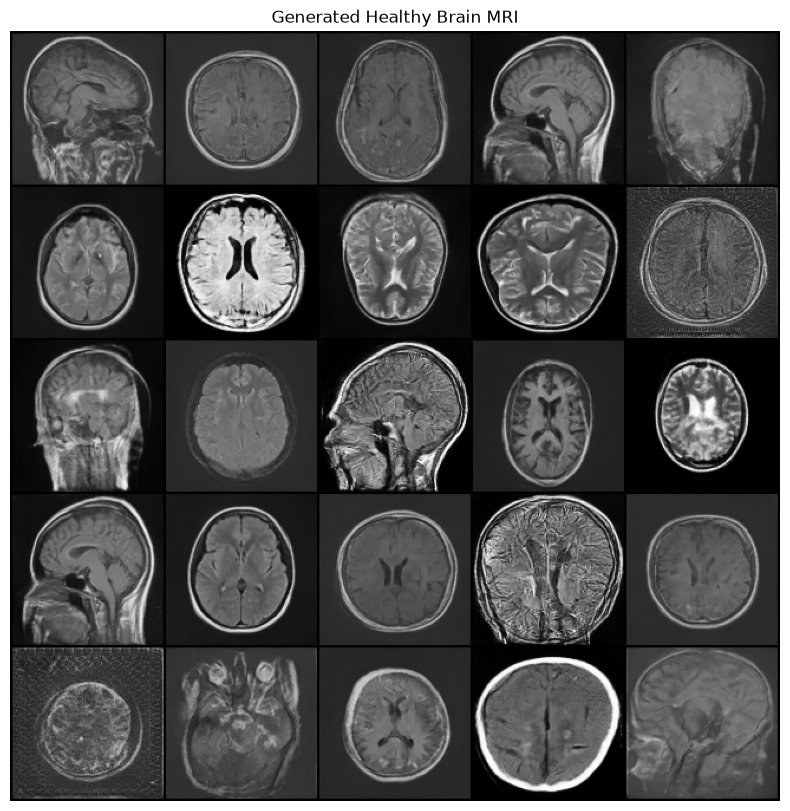

In [17]:
import torch, torch.nn as nn, torchvision
import matplotlib.pyplot as plt

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
CKPT = r"F:\Work\Python Learning\Healthy MRI of Brain v2.pth"   # or mri_dcgan_epochXXX.pth
USE_EMA = True

class Generator(nn.Module):
    def __init__(self, noise_dim=100):
        super().__init__()
        def up(i, o):
            return [nn.ConvTranspose2d(i, o, 4, 2, 1, bias=False), nn.BatchNorm2d(o), nn.ReLU(True)]
        self.layers = nn.Sequential(
            nn.ConvTranspose2d(noise_dim, 512, 4, 1, 0, bias=False), nn.BatchNorm2d(512), nn.ReLU(True),
            *up(512, 512), *up(512, 256), *up(256, 128), *up(128, 64),
            nn.ConvTranspose2d(64, 3, 4, 2, 1, bias=False),
            nn.Tanh(),
        )
    def forward(self, x):
        return self.layers(x)

ckpt = torch.load(CKPT, map_location=device)
nz = ckpt.get("noise_dim", 100)
G = Generator(nz).to(device)
G.load_state_dict(ckpt["G_ema" if USE_EMA else "G"])
G.eval()

with torch.no_grad():
    imgs = (G(torch.randn(25, nz, 1, 1, device=device)) + 1) / 2

grid = torchvision.utils.make_grid(imgs.cpu(), nrow=5)
plt.figure(figsize=(10, 10)); plt.imshow(grid.permute(1, 2, 0)); plt.axis("off")
plt.title("Generated Healthy Brain MRI"); plt.show()